<a href="https://colab.research.google.com/github/Nina-Cyndy/diabetes-intro-to-ml-summative/blob/main/diabetes_readmission.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicting 30-Day Hospital Readmission in Diabetic Patients
**Summative Project: Machine Learning (traditional ML vs. deep learning)**

**Task:** multi-class classification of `readmitted` (`<30`, `>30`, `NO`) using the *Diabetes 130-US Hospitals (1999-2008)* dataset from the UCI Machine Learning Repository.

**Notebook map**

| Section | Content | Status |
|---|---|---|
| 1 | Setup, seeds and configuration | Day 1 |
| 2 | Data loading | Day 1 |
| 3 | Exploratory data analysis | Day 1 |
| 4 | Data cleaning and patient-level split | Day 1 |
| 5 | Feature engineering | Day 2 |
| 6 | Traditional ML (scikit-learn) | Day 2 |
| 7 | Deep learning (TensorFlow/Keras + `tf.data`) | Day 3 |
| 8 | Evaluation and error analysis | Day 4 |
| 9 | Experiment table and conclusions | Day 4 |

**Running on Google Colab:** upload `diabetic_data.csv` and `IDs_mapping.csv` into a `data/` folder (or mount Drive and change `DATA_DIR` in section 1), then run all cells from the top.

## 1. Setup, seeds and configuration
All randomness is controlled by a single `SEED`, and all paths are defined once in this cell so the notebook is reproducible from top to bottom. Weights & Biases is forced into **offline mode** so runs are logged locally without an account (the rubric asks for W&B offline or TensorBoard logs backing the experiment table).

In [ ]:
# Uncomment on Colab / a fresh environment
!pip install -q -r requirements.txt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 18.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 947.5/947.5 kB 17.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.5/77.5 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.2/60.2 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 17.5 MB/s eta 0:00:00


In [ ]:
import os, random, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupShuffleSplit
from google.colab import drive

warnings.filterwarnings("ignore")
drive.mount("/content/drive")

# ---- Reproducibility ----
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
try:
    import tensorflow as tf
    tf.random.set_seed(SEED)
    print("TensorFlow", tf.__version__)
except ImportError:
    print("TensorFlow not installed here (needed from Section 7 onwards).")

PROJECT_DIR = Path("/content/drive/MyDrive/diabetes_project")

DATA_DIR = PROJECT_DIR / "data"                 # diabetic_data.csv + IDs_mapping.csv go here
PROCESSED_DIR = DATA_DIR / "processed"          # cleaned train/val/test splits
FIG_DIR = PROJECT_DIR / "figures"               # all saved plots
MODEL_DIR = PROJECT_DIR / "saved_models"        # .joblib and .h5 / SavedModel files
LOG_DIR = PROJECT_DIR / "logs"                  # TensorBoard logs

# ---- Weights & Biases offline mode ----
os.environ["WANDB_MODE"] = "offline"
os.environ["WANDB_DIR"] = str(PROJECT_DIR)

for d in (DATA_DIR, PROCESSED_DIR, FIG_DIR, MODEL_DIR, LOG_DIR):
    d.mkdir(parents=True, exist_ok=True)

DATA_FILE = DATA_DIR / "diabetic_data.csv"
TARGET = "readmitted"
CLASS_ORDER = ["NO", ">30", "<30"]

ID_CODE_COLS = ["admission_type_id", "discharge_disposition_id", "admission_source_id"]
NUM_COLS = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
            "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"]
# discharge_disposition_id values meaning the patient died or went to hospice (see IDs_mapping.csv)
EXPIRED_HOSPICE_IDS = [11, 13, 14, 19, 20, 21]

sns.set_theme(style="whitegrid", context="notebook")

Mounted at /content/drive
TensorFlow 2.21.0


## 2. Data loading
In this file, missing values are coded as the string `"?"`. I convert them to real `NaN` while loading. Default pandas NA-parsing is switched off on purpose: the strings `"None"` (in `A1Cresult` and `max_glu_serum`) and `"NO"` (in the target) are **valid categories**, not missing values. `"None"` means the test was not performed, which can itself be clinically informative.

In [ ]:
def load_raw(path: Path) -> pd.DataFrame:
    """Load the raw CSV, treating only '?' as missing."""
    return pd.read_csv(path, na_values=["?"], keep_default_na=False, low_memory=False)

raw = load_raw(DATA_FILE)
assert len(raw) >= 20_000, "Brief requires at least 20,000 raw rows"
print(f"Raw shape: {raw.shape[0]:,} rows x {raw.shape[1]} columns  (brief minimum: 20,000 rows)")
raw.head()

Raw shape: 101,766 rows x 50 columns  (brief minimum: 20,000 rows)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [ ]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      99493 non-null   object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    3197 non-null    object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                61510 non-null   object
 11  medical_specialty         51817 non-null   object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

## 3. Exploratory data analysis
Each analysis below is followed by a short interpretation cell. **Fill in the interpretation cells in your own words after you look at the output**; the written report draws directly on them.

### 3.1 Target distribution

,count,percent
readmitted,,
NO,54864,53.91
>30,35545,34.93
<30,11357,11.16


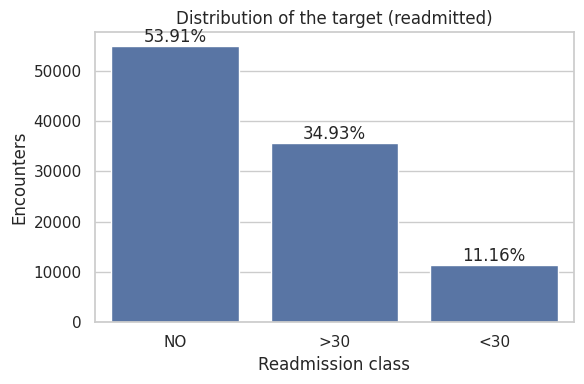

In [ ]:
counts = raw[TARGET].value_counts().reindex(CLASS_ORDER)
pct = (counts / counts.sum() * 100).round(2)
display(pd.DataFrame({"count": counts, "percent": pct}))

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=counts.index, y=counts.values, ax=ax, order=CLASS_ORDER)
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{pct.iloc[i]}%", ha="center", va="bottom")
ax.set(title="Distribution of the target (readmitted)", xlabel="Readmission class", ylabel="Encounters")
plt.tight_layout(); plt.savefig(FIG_DIR / "target_distribution.png", dpi=200); plt.show()

**Interpretation (write your own):** How imbalanced is the target? Which class is the minority, and why does that matter for choosing metrics (macro-F1, per-class recall, ROC-AUC) instead of plain accuracy?

### 3.2 Missing values

In [ ]:
def missing_report(df: pd.DataFrame) -> pd.DataFrame:
    m = df.isna().sum()
    out = pd.DataFrame({"missing": m, "percent": (m / len(df) * 100).round(2)})
    return out[out["missing"] > 0].sort_values("percent", ascending=False)

missing_report(raw)

,missing,percent
weight,98569,96.86
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02


**Interpretation (write your own):** Which columns have the most missing data? Decide for each (drop, impute, or keep as an explicit "Unknown" category) and justify it. The defaults used in Section 4 are: drop `weight`, label missing `race`, `payer_code` and `medical_specialty` as "Unknown".

### 3.3 Numeric features: distributions and outliers

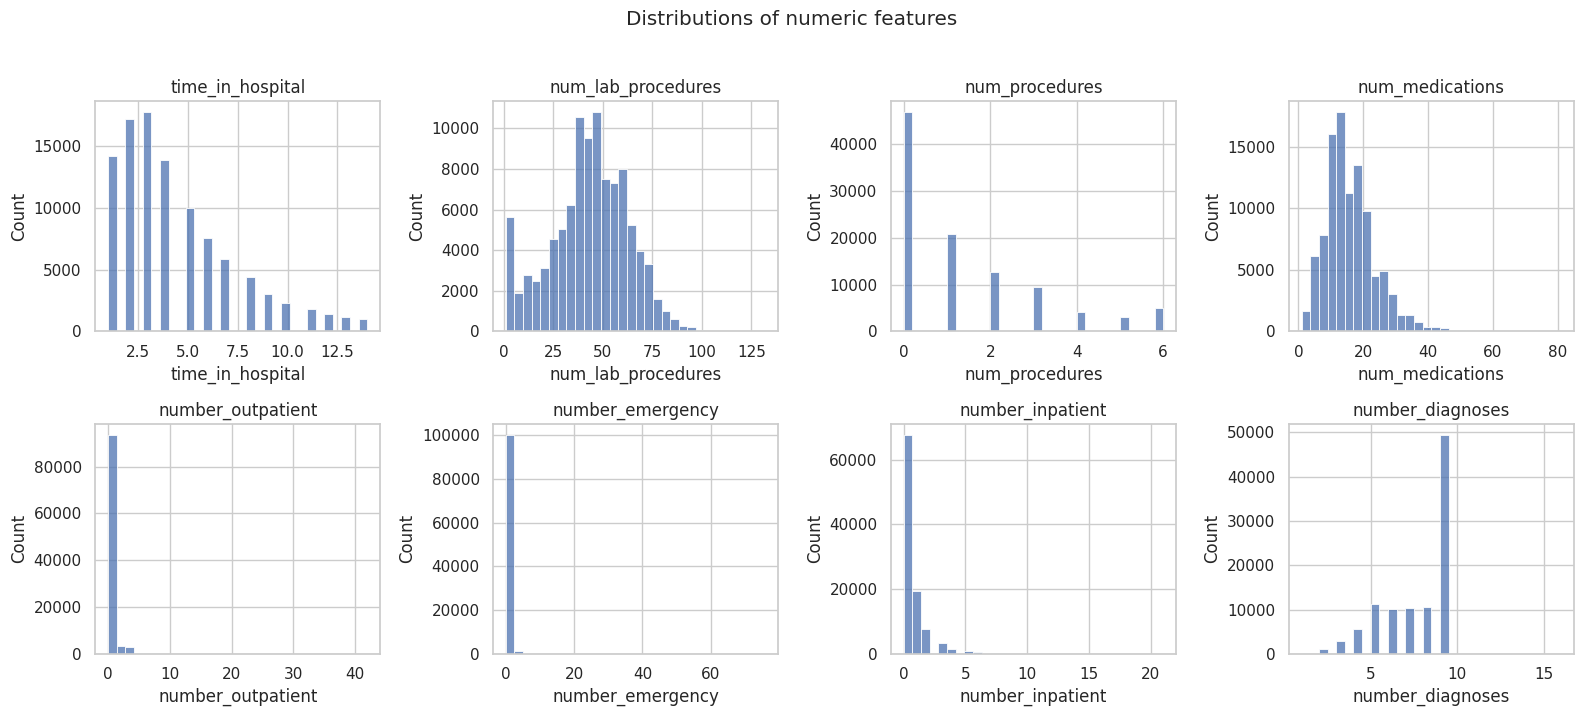

,min,median,max,outliers_IQR,outlier_pct
feature,,,,,
time_in_hospital,1,4.0,14,2252,2.21
num_lab_procedures,1,44.0,132,143,0.14
num_procedures,0,1.0,6,4954,4.87
num_medications,1,15.0,81,2557,2.51
number_outpatient,0,0.0,42,16739,16.45
number_emergency,0,0.0,76,11383,11.19
number_inpatient,0,0.0,21,7049,6.93
number_diagnoses,1,8.0,16,281,0.28


In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), NUM_COLS):
    sns.histplot(raw[col], bins=30, ax=ax)
    ax.set_title(col)
plt.suptitle("Distributions of numeric features", y=1.02)
plt.tight_layout(); plt.savefig(FIG_DIR / "numeric_distributions.png", dpi=200, bbox_inches="tight"); plt.show()

def iqr_outlier_table(df: pd.DataFrame, cols) -> pd.DataFrame:
    rows = []
    for c in cols:
        q1, q3 = df[c].quantile([0.25, 0.75])
        iqr = q3 - q1
        n_out = ((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum()
        rows.append({"feature": c, "min": df[c].min(), "median": df[c].median(), "max": df[c].max(),
                     "outliers_IQR": n_out, "outlier_pct": round(n_out / len(df) * 100, 2)})
    return pd.DataFrame(rows).set_index("feature")

iqr_outlier_table(raw, NUM_COLS)

**Interpretation (write your own):** Which features are right-skewed or have long tails? Are the extreme values plausible clinically (e.g., many prior visits) or errors? Decide whether to clip, log-transform, or leave them, since tree models and neural networks react differently to skew.

### 3.4 Readmission rate against key features

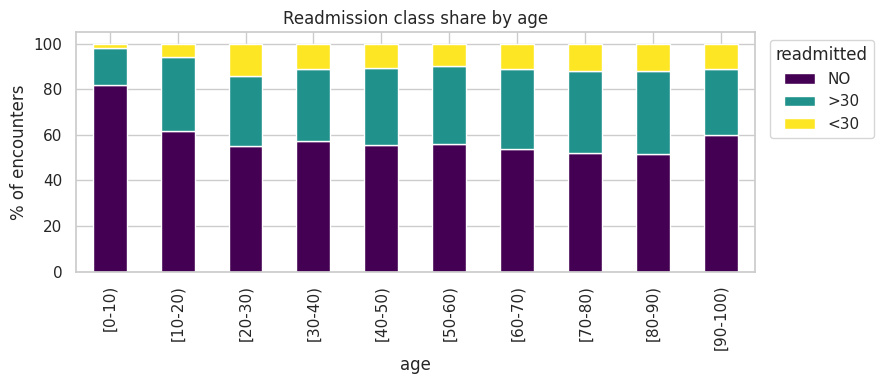

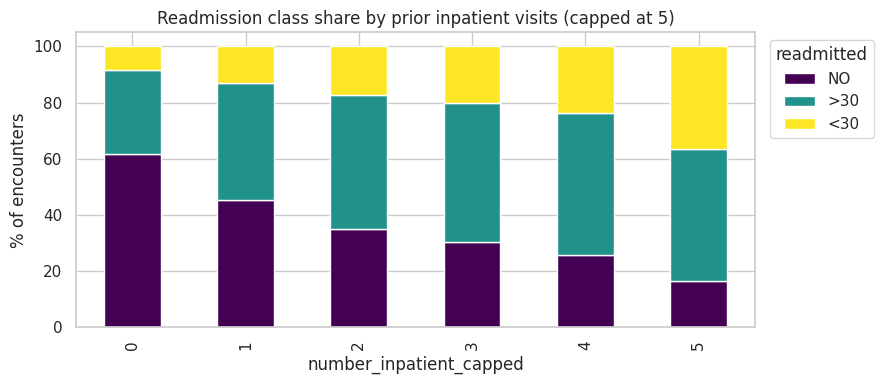

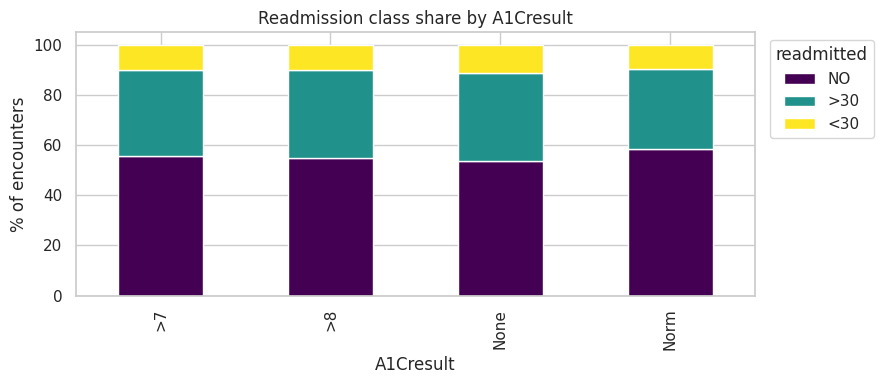

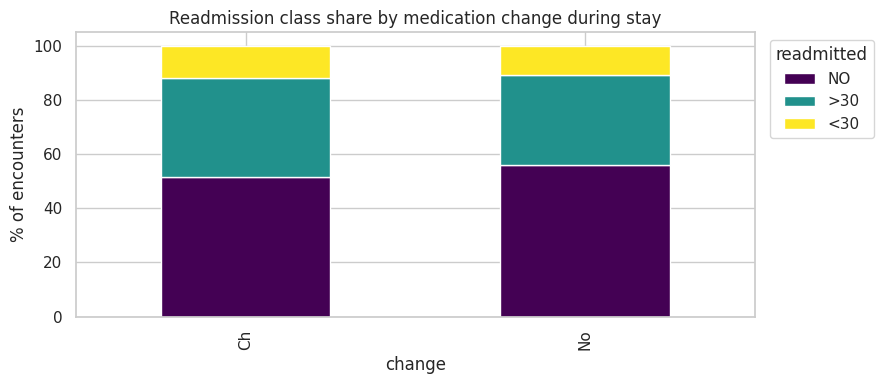

In [ ]:
def class_share_plot(df: pd.DataFrame, col: str, order=None, title=None, fname=None):
    ct = pd.crosstab(df[col], df[TARGET], normalize="index")[CLASS_ORDER] * 100
    if order is not None:
        ct = ct.reindex(order)
    ax = ct.plot(kind="bar", stacked=True, figsize=(9, 4), colormap="viridis")
    ax.set(title=title or f"Readmission class share by {col}", ylabel="% of encounters", xlabel=col)
    ax.legend(title=TARGET, bbox_to_anchor=(1.01, 1), loc="upper left")
    plt.tight_layout()
    if fname:
        plt.savefig(FIG_DIR / fname, dpi=200)
    plt.show()

age_order = sorted(raw["age"].unique(), key=lambda s: int(s.strip("[").split("-")[0]))
class_share_plot(raw, "age", order=age_order, fname="readmit_by_age.png")

tmp = raw.assign(number_inpatient_capped=raw["number_inpatient"].clip(upper=5))
class_share_plot(tmp, "number_inpatient_capped", title="Readmission class share by prior inpatient visits (capped at 5)",
                 fname="readmit_by_prior_inpatient.png")
class_share_plot(raw, "A1Cresult", fname="readmit_by_a1c.png")
class_share_plot(raw, "change", title="Readmission class share by medication change during stay", fname="readmit_by_change.png")

**Interpretation (write your own):** Which features visibly shift the class mix? (Prior inpatient visits is usually the strongest signal.) Do the patterns match what you found in the literature?

### 3.5 Correlation among numeric features

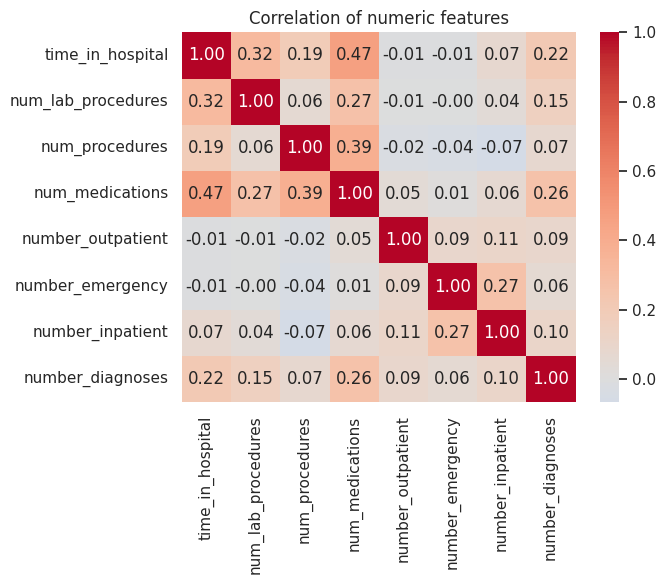

In [ ]:
corr = raw[NUM_COLS].corr()
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation of numeric features")
plt.tight_layout(); plt.savefig(FIG_DIR / "correlation_heatmap.png", dpi=200); plt.show()

**Interpretation (write your own):** Are any features strongly correlated (e.g., `time_in_hospital` and `num_medications`)? What does that imply for linear models (multicollinearity) versus tree-based models?

### 3.6 Near-constant columns

In [ ]:
def near_constant_report(df: pd.DataFrame, threshold: float = 0.99) -> pd.DataFrame:
    rows = []
    for c in df.select_dtypes(include="object").columns:
        top_share = df[c].value_counts(normalize=True, dropna=False).iloc[0]
        if top_share >= threshold:
            rows.append({"column": c, "top_value": df[c].value_counts(dropna=False).index[0],
                         "top_share_pct": round(top_share * 100, 2)})
    return pd.DataFrame(rows).set_index("column") if rows else pd.DataFrame()

near_constant_report(raw)

,top_value,top_share_pct
column,,
nateglinide,No,99.31
chlorpropamide,No,99.92
acetohexamide,No,100.00
tolbutamide,No,99.98
acarbose,No,99.70
miglitol,No,99.96
troglitazone,No,100.00
tolazamide,No,99.96
examide,No,100.00


**Interpretation (write your own):** Which medication columns carry almost no information? Constant columns are dropped in Section 4; near-constant ones may be kept, grouped, or dropped, so state which you chose and why.

### 3.7 Repeat patients (leakage check)

In [ ]:
enc_per_patient = raw.groupby("patient_nbr").size()
repeat_patients = (enc_per_patient > 1).sum()
rows_from_repeat = enc_per_patient[enc_per_patient > 1].sum()

print(f"Unique patients: {enc_per_patient.shape[0]:,}")
print(f"Patients with >1 encounter: {repeat_patients:,} ({repeat_patients / enc_per_patient.shape[0]:.1%} of patients)")
print(f"Encounters belonging to repeat patients: {rows_from_repeat:,} ({rows_from_repeat / len(raw):.1%} of rows)")
print(f"Max encounters for one patient: {enc_per_patient.max()}")

Unique patients: 71,518
Patients with >1 encounter: 16,773 (23.5% of patients)
Encounters belonging to repeat patients: 47,021 (46.2% of rows)
Max encounters for one patient: 40


**Interpretation (write your own):** A random row-level split would put encounters from the *same patient* in both train and test, so the model could memorize patient-specific patterns and the test score would be optimistic (data leakage). Section 4 therefore splits **by patient**. State this as a methodological choice in the report.

## 4. Data cleaning and patient-level split
Cleaning decisions, each tied to the EDA above:

1. **Remove encounters ending in death or hospice** (`discharge_disposition_id` in 11, 13, 14, 19, 20, 21): these patients cannot be readmitted, so keeping them would bias the target.
2. **Remove the few `Unknown/Invalid` gender rows**: too few to model.
3. **Drop `weight`** (almost entirely missing) and `encounter_id` (identifier with no predictive meaning).
4. **Label missing `race`, `payer_code`, `medical_specialty` and diagnosis codes as "Unknown"**, keeping missingness as potential signal rather than guessing values.
5. **Drop constant columns** (zero information).
6. **Treat admission/discharge/source IDs as categorical**, since they are codes, not quantities.

`patient_nbr` is kept for now because it is needed for the group split; it is **dropped before modeling** (Section 5).

In [ ]:
def clean_data(df: pd.DataFrame) -> pd.DataFrame:
    """Apply all cleaning decisions documented above. Returns a new DataFrame."""
    out = df.copy()
    n0 = len(out)

    out = out[~out["discharge_disposition_id"].isin(EXPIRED_HOSPICE_IDS)]
    n1 = len(out)
    out = out[out["gender"] != "Unknown/Invalid"]
    n2 = len(out)

    out = out.drop(columns=[c for c in ["weight", "encounter_id"] if c in out.columns])

    for col in ["race", "payer_code", "medical_specialty", "diag_1", "diag_2", "diag_3"]:
        out[col] = out[col].fillna("Unknown")

    constant_cols = [c for c in out.columns if out[c].nunique(dropna=False) == 1]
    out = out.drop(columns=constant_cols)

    for col in ID_CODE_COLS:
        out[col] = out[col].astype(str)

    print(f"Removed {n0 - n1:,} expired/hospice encounters and {n1 - n2:,} invalid-gender rows")
    print(f"Dropped constant columns: {constant_cols}")
    print(f"Clean shape: {out.shape[0]:,} rows x {out.shape[1]} columns")
    return out.reset_index(drop=True)

clean = clean_data(raw)
assert clean.drop(columns=["patient_nbr"]).isna().sum().sum() == 0, "Unexpected missing values remain"
clean.head()

Removed 2,423 expired/hospice encounters and 3 invalid-gender rows
Dropped constant columns: ['examide', 'citoglipton']
Clean shape: 99,340 rows x 46 columns


,patient_nbr,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,...,tolazamide,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,8222157,Caucasian,Female,[0-10),6,25,1,1,Unknown,Pediatrics-Endocrinology,...,No,No,No,No,No,No,No,No,No,NO
1,55629189,Caucasian,Female,[10-20),1,1,7,3,Unknown,Unknown,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,86047875,AfricanAmerican,Female,[20-30),1,1,7,2,Unknown,Unknown,...,No,No,No,No,No,No,No,No,Yes,NO
3,82442376,Caucasian,Male,[30-40),1,1,7,2,Unknown,Unknown,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,42519267,Caucasian,Male,[40-50),1,1,7,1,Unknown,Unknown,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [ ]:
def split_by_patient(df: pd.DataFrame, val_size: float = 0.15, test_size: float = 0.15, seed: int = SEED):
    """Train/val/test split where no patient appears in more than one subset."""
    gss = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
    trainval_idx, test_idx = next(gss.split(df, groups=df["patient_nbr"]))
    trainval, test = df.iloc[trainval_idx], df.iloc[test_idx]

    gss2 = GroupShuffleSplit(n_splits=1, test_size=val_size / (1 - test_size), random_state=seed)
    train_idx, val_idx = next(gss2.split(trainval, groups=trainval["patient_nbr"]))
    return trainval.iloc[train_idx].copy(), trainval.iloc[val_idx].copy(), test.copy()

train_df, val_df, test_df = split_by_patient(clean)

# Leakage check: no patient may appear in two subsets
p_tr, p_va, p_te = (set(d["patient_nbr"]) for d in (train_df, val_df, test_df))
assert not (p_tr & p_va or p_tr & p_te or p_va & p_te), "Patient leakage between splits!"

summary = pd.DataFrame({
    "rows": [len(train_df), len(val_df), len(test_df)],
    "patients": [len(p_tr), len(p_va), len(p_te)],
}, index=["train", "validation", "test"])
summary["row_share_%"] = (summary["rows"] / summary["rows"].sum() * 100).round(1)
display(summary)

class_mix = pd.concat({n: d[TARGET].value_counts(normalize=True).reindex(CLASS_ORDER) * 100
                       for n, d in [("train", train_df), ("validation", val_df), ("test", test_df)]}, axis=1).round(2)
display(class_mix.rename_axis("class (% of split)"))

,rows,patients,row_share_%
train,69702,48990,70.2
validation,14823,10498,14.9
test,14815,10499,14.9


,train,validation,test
class (% of split),,,
NO,52.62,53.35,53.59
>30,35.92,35.33,35.31
<30,11.47,11.32,11.10


**Interpretation (write your own):** Confirm the class proportions are similar across splits, so validation and test scores are comparable to training. Record the final split sizes in the experiment table's "dataset splits" column.

In [ ]:
train_df.to_csv(PROCESSED_DIR / "train.csv", index=False)
val_df.to_csv(PROCESSED_DIR / "val.csv", index=False)
test_df.to_csv(PROCESSED_DIR / "test.csv", index=False)
print("Saved cleaned splits to", PROCESSED_DIR.resolve())

Saved cleaned splits to /content/drive/MyDrive/diabetes_project/data/processed


## 5. Feature engineering
The cleaned data keeps raw ICD-9 diagnosis codes (hundreds of distinct values), age brackets, and 21 medication columns. This section builds an **engineered feature set** and compares it against a **baseline feature set** (cleaned columns used as they are), so the value of feature engineering is measured and not just asserted.

| Engineered feature | Rationale |
|---|---|
| `diag_1/2/3_group` | Collapse ~700 ICD-9 codes into 9 clinical groups (circulatory, respiratory, diabetes, ...) following the grouping of Strack et al. (2014) |
| `age_mid` | Ordered age brackets become a numeric midpoint, so models can use their order |
| `log_number_*`, `log_total_prior_visits`, `has_prior_inpatient` | Prior-visit counts are heavily right-skewed (EDA 3.3); log-scaling helps linear and neural models, and prior inpatient history is the strongest readmission signal in the literature |
| `n_meds_active`, `n_meds_changed` | Summarise 21 sparse medication columns into treatment intensity and treatment change |
| `meds_per_day`, `labs_per_day` | Normalise workload by length of stay |
| `a1c_tested`, `glu_tested`, `a1c_tested_and_changed` | Testing behaviour and its interaction with a medication change (the central finding of the original dataset paper) |

The near-constant medication columns found in EDA 3.6 (at least 99% "No" in the training set) are dropped from the engineered set, because `n_meds_active` and `n_meds_changed` already capture them. All transformations here are **row-wise and stateless**, so applying them before fitting any model introduces no leakage. Anything that learns statistics (scaling, one-hot categories, rare-category grouping) lives inside the scikit-learn pipeline and is fitted on training data only.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

MED_COLS = ["metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride", "acetohexamide",
            "glipizide", "glyburide", "tolbutamide", "pioglitazone", "rosiglitazone", "acarbose", "miglitol",
            "troglitazone", "tolazamide", "insulin", "glyburide-metformin", "glipizide-metformin",
            "glimepiride-pioglitazone", "metformin-rosiglitazone", "metformin-pioglitazone"]
MED_COLS = [c for c in MED_COLS if c in train_df.columns]          # constant columns were already dropped
RARE_MED_COLS = [c for c in MED_COLS if (train_df[c] == "No").mean() >= 0.99]   # decided from TRAIN only
print(f"{len(MED_COLS)} medication columns, {len(RARE_MED_COLS)} near-constant ones dropped from the engineered set")

LABEL_MAP = {c: i for i, c in enumerate(CLASS_ORDER)}              # NO=0, >30=1, <30=2
LABELS = list(LABEL_MAP.values())


def icd9_to_group(code: str) -> str:
    """Map an ICD-9 code to one of 9 broad clinical groups (grouping follows Strack et al., 2014)."""
    code = str(code)
    if code == "Unknown":
        return "Unknown"
    if code.startswith(("V", "E")):
        return "Other"
    try:
        v = float(code)
    except ValueError:
        return "Other"
    if 250 <= v < 251:                       return "Diabetes"
    if 390 <= v < 460 or int(v) == 785:      return "Circulatory"
    if 460 <= v < 520 or int(v) == 786:      return "Respiratory"
    if 520 <= v < 580 or int(v) == 787:      return "Digestive"
    if 580 <= v < 630 or int(v) == 788:      return "Genitourinary"
    if 710 <= v < 740:                       return "Musculoskeletal"
    if 800 <= v < 1000:                      return "Injury"
    if 140 <= v < 240:                       return "Neoplasms"
    return "Other"


def age_midpoint(bracket: str) -> int:
    """'[50-60)' -> 55"""
    return int(bracket.strip("[)").split("-")[0]) + 5


def engineer_features(df: pd.DataFrame) -> pd.DataFrame:
    """Stateless row-wise feature engineering. Expects a frame without the target and patient id."""
    out = df.copy()

    for c in ["diag_1", "diag_2", "diag_3"]:
        out[f"{c}_group"] = out[c].map(icd9_to_group)
    out["age_mid"] = out["age"].map(age_midpoint)

    out["total_prior_visits"] = out[["number_outpatient", "number_emergency", "number_inpatient"]].sum(axis=1)
    out["has_prior_inpatient"] = (out["number_inpatient"] > 0).astype(int)
    for c in ["number_outpatient", "number_emergency", "number_inpatient", "total_prior_visits"]:
        out[f"log_{c}"] = np.log1p(out[c])

    meds = out[MED_COLS]
    out["n_meds_active"] = (meds != "No").sum(axis=1)
    out["n_meds_changed"] = meds.isin(["Up", "Down"]).sum(axis=1)
    out["meds_per_day"] = out["num_medications"] / out["time_in_hospital"]
    out["labs_per_day"] = out["num_lab_procedures"] / out["time_in_hospital"]

    out["a1c_tested"] = (out["A1Cresult"] != "None").astype(int)
    out["glu_tested"] = (out["max_glu_serum"] != "None").astype(int)
    out["a1c_tested_and_changed"] = ((out["A1Cresult"] != "None") & (out["change"] == "Ch")).astype(int)

    drop = (["diag_1", "diag_2", "diag_3", "age", "number_outpatient", "number_emergency",
             "number_inpatient", "total_prior_visits"] + RARE_MED_COLS)
    return out.drop(columns=drop)


def make_xy(df: pd.DataFrame, engineered: bool):
    """Return features X and integer-encoded target y. patient_nbr is never a feature."""
    X = df.drop(columns=[TARGET, "patient_nbr"]).copy()
    for c in X.columns:                       # guard: categorical columns must be uniformly strings
        if not pd.api.types.is_numeric_dtype(X[c]):
            X[c] = X[c].astype(str)
    if engineered:
        X = engineer_features(X)
    return X.reset_index(drop=True), df[TARGET].map(LABEL_MAP).values


X_tr_base, y_tr = make_xy(train_df, engineered=False)
X_va_base, y_va = make_xy(val_df, engineered=False)
X_te_base, y_te = make_xy(test_df, engineered=False)

X_tr_eng, _ = make_xy(train_df, engineered=True)
X_va_eng, _ = make_xy(val_df, engineered=True)
X_te_eng, _ = make_xy(test_df, engineered=True)

groups_tr = train_df["patient_nbr"].values        # used to keep patients together inside cross-validation
print(f"Baseline features:   {X_tr_base.shape[1]} columns")
print(f"Engineered features: {X_tr_eng.shape[1]} columns")
assert X_tr_eng.isna().sum().sum() == 0 and X_va_eng.isna().sum().sum() == 0 and X_te_eng.isna().sum().sum() == 0
X_tr_eng.head()

21 medication columns, 13 near-constant ones dropped from the engineered set
Baseline features:   44 columns
Engineered features: 40 columns


,race,gender,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,...,log_number_emergency,log_number_inpatient,log_total_prior_visits,n_meds_active,n_meds_changed,meds_per_day,labs_per_day,a1c_tested,glu_tested,a1c_tested_and_changed
0,Caucasian,Female,6,25,1,1,Unknown,Pediatrics-Endocrinology,41,0,...,0.0,0.000000,0.000000,0,0,1.0,41.000000,0,0,0
1,Caucasian,Female,1,1,7,3,Unknown,Unknown,59,0,...,0.0,0.000000,0.000000,1,1,6.0,19.666667,0,0,0
2,AfricanAmerican,Female,1,1,7,2,Unknown,Unknown,11,5,...,0.0,0.693147,1.386294,1,0,6.5,5.500000,0,0,0
3,Caucasian,Male,1,1,7,2,Unknown,Unknown,44,1,...,0.0,0.000000,0.000000,1,1,8.0,22.000000,0,0,0
4,Caucasian,Male,1,1,7,1,Unknown,Unknown,51,0,...,0.0,0.000000,0.000000,2,0,8.0,51.000000,0,0,0


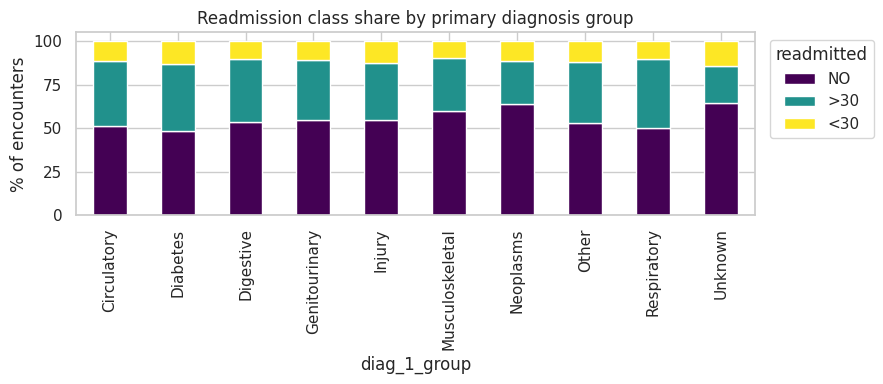

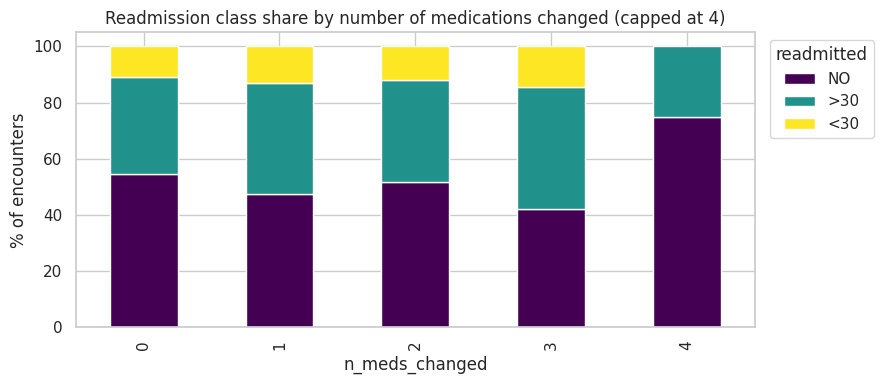

In [ ]:
# Quick check that the engineered diagnosis groups carry signal about readmission
tmp = X_tr_eng.assign(**{TARGET: train_df[TARGET].values})
class_share_plot(tmp, "diag_1_group", title="Readmission class share by primary diagnosis group",
                 fname="readmit_by_diag1_group.png")
class_share_plot(tmp.assign(n_meds_changed=tmp["n_meds_changed"].clip(upper=4)), "n_meds_changed",
                 title="Readmission class share by number of medications changed (capped at 4)",
                 fname="readmit_by_meds_changed.png")

**Interpretation (write your own):** Do primary diagnosis groups differ in their readmission mix? Does the number of medication changes shift it? State which engineered features look most promising before the models confirm it in Section 6.

In [ ]:
def split_cols(X: pd.DataFrame):
    cat_cols = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]
    num_cols = [c for c in X.columns if c not in cat_cols]
    return num_cols, cat_cols


def build_preprocessor(X: pd.DataFrame) -> ColumnTransformer:
    """Scale numeric columns; one-hot encode categoricals. Categories seen in under 1% of the training
    rows are pooled into one 'infrequent' bucket, which also tames high-cardinality columns such as
    medical_specialty and the raw ICD-9 codes in the baseline set."""
    num_cols, cat_cols = split_cols(X)
    return ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.01,
                              sparse_output=False), cat_cols),
    ])


def make_pipeline(X: pd.DataFrame, clf) -> Pipeline:
    return Pipeline([("prep", build_preprocessor(X)), ("clf", clf)])


n_base = build_preprocessor(X_tr_base).fit(X_tr_base).get_feature_names_out().shape[0]
n_eng = build_preprocessor(X_tr_eng).fit(X_tr_eng).get_feature_names_out().shape[0]
print(f"Model-ready columns after encoding: baseline = {n_base}, engineered = {n_eng}")

Model-ready columns after encoding: baseline = 200, engineered = 136


## 6. Traditional machine learning (scikit-learn)
Every experiment goes through one function, `run_experiment`, so each run is logged **identically** to (a) an in-memory experiment table that is saved to Drive as `experiment_log.csv`, and (b) a Weights & Biases run in offline mode (stored under `wandb/` in your Drive folder). This is what makes the experiment table traceable to real logged runs.

**Metrics.** Accuracy alone is misleading with 11% in the `<30` class, so each run records macro-F1 (the main selection metric), weighted-F1, macro one-vs-rest ROC-AUC, and recall and AUC for the clinically important `<30` class. Training macro-F1 is logged next to validation macro-F1 so the gap (variance) is visible for every model.

**Selection rule.** Models are compared on the **validation** set only. The test set is not touched until the final evaluation in Section 8.

In [ ]:
import json, time, joblib
from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score

try:
    import wandb
    WANDB_OK = True
except ImportError:
    WANDB_OK = False
    print("wandb not installed: runs will only be logged to the experiment table.")

os.environ["WANDB_SILENT"] = "true"          # keep the notebook output readable; logs still go to Drive
WANDB_PROJECT = "diabetes-readmission"
EXP_CSV = PROJECT_DIR / "experiment_log.csv"
EXPERIMENT_LOG, FITTED = [], {}


def evaluate(pipe, X, y) -> dict:
    proba = pipe.predict_proba(X)
    pred = proba.argmax(axis=1)
    rec = recall_score(y, pred, average=None, labels=LABELS, zero_division=0)
    return {
        "accuracy": accuracy_score(y, pred),
        "f1_macro": f1_score(y, pred, average="macro"),
        "f1_weighted": f1_score(y, pred, average="weighted"),
        "precision_macro": precision_score(y, pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y, pred, average="macro"),
        "roc_auc_ovr_macro": roc_auc_score(y, proba, multi_class="ovr", average="macro"),
        "recall_lt30": rec[LABEL_MAP["<30"]],
        "auc_lt30": roc_auc_score((y == LABEL_MAP["<30"]).astype(int), proba[:, LABEL_MAP["<30"]]),
    }


def run_experiment(name, pipe, X_tr, y_tr, X_va, y_va, feature_set, params, notes="",
                   prefix="ML", fit=True, fit_time=None):
    """Fit (optionally), evaluate on train and validation, log to the table and to W&B (offline)."""
    exp_id = f"{prefix}-{sum(r['exp_id'].startswith(prefix) for r in EXPERIMENT_LOG) + 1:02d}"
    if fit:
        t0 = time.time()
        pipe.fit(X_tr, y_tr)
        fit_time = time.time() - t0
    tr, va = evaluate(pipe, X_tr, y_tr), evaluate(pipe, X_va, y_va)

    row = {"exp_id": exp_id, "name": name, "feature_set": feature_set,
           "n_features_in": X_tr.shape[1], "params": json.dumps(params, default=str),
           "split": f"train {len(y_tr):,} / val {len(y_va):,} (patient-level)",
           "train_f1_macro": round(tr["f1_macro"], 4),
           **{f"val_{k}": round(v, 4) for k, v in va.items()},
           "f1_gap_train_minus_val": round(tr["f1_macro"] - va["f1_macro"], 4),
           "fit_time_s": round(fit_time, 1), "notes": notes}
    EXPERIMENT_LOG.append(row)
    FITTED[exp_id] = pipe
    pd.DataFrame(EXPERIMENT_LOG).to_csv(EXP_CSV, index=False)

    if WANDB_OK:
        run = wandb.init(project=WANDB_PROJECT, name=f"{exp_id}_{name}", dir=str(PROJECT_DIR),
                         config={"family": prefix, "feature_set": feature_set, **params})
        wandb.log({k: v for k, v in row.items() if isinstance(v, (int, float))})
        wandb.finish()

    print(f"{exp_id} | {name:<38} | val macro-F1 {va['f1_macro']:.4f} | val acc {va['accuracy']:.4f} | "
          f"val AUC {va['roc_auc_ovr_macro']:.4f} | train-val F1 gap {tr['f1_macro'] - va['f1_macro']:+.3f} | {fit_time:.0f}s")

### 6.1 Does feature engineering help? (baseline vs. engineered, two model families)
The same two algorithms are trained on both feature sets with default hyperparameters, so any difference comes from the features alone: a linear model (Logistic Regression) and a tree ensemble (Random Forest).

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

feature_sets = {"baseline": (X_tr_base, X_va_base), "engineered": (X_tr_eng, X_va_eng)}

for fs_name, (Xa, Xb) in feature_sets.items():
    run_experiment("LogReg default", make_pipeline(Xa, LogisticRegression(max_iter=1000, random_state=SEED)),
                   Xa, y_tr, Xb, y_va, fs_name, {"model": "LogisticRegression", "C": 1.0, "class_weight": None})

for fs_name, (Xa, Xb) in feature_sets.items():
    run_experiment("RandomForest default",
                   make_pipeline(Xa, RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED)),
                   Xa, y_tr, Xb, y_va, fs_name,
                   {"model": "RandomForest", "n_estimators": 200, "max_depth": None, "class_weight": None})

ML-01 | LogReg default                         | val macro-F1 0.3850 | val acc 0.5769 | val AUC 0.6635 | train-val F1 gap +0.002 | 37s
ML-02 | LogReg default                         | val macro-F1 0.3844 | val acc 0.5774 | val AUC 0.6583 | train-val F1 gap +0.006 | 16s
ML-03 | RandomForest default                   | val macro-F1 0.3811 | val acc 0.5778 | val AUC 0.6602 | train-val F1 gap +0.619 | 54s
ML-04 | RandomForest default                   | val macro-F1 0.3778 | val acc 0.5728 | val AUC 0.6583 | train-val F1 gap +0.622 | 48s


**Interpretation (write your own):** Compare baseline against engineered for each model. Did feature engineering help the linear model more than the forest (or the other way round)? Why might that be (think about skew, one-hot dimensionality and what trees can already learn from raw values)? Look at the train-vs-validation F1 gap of the default Random Forest and explain what it says about variance.

### 6.2 Class imbalance and model diversity (engineered features)
Three more experiments on the engineered set: **class weighting** for both earlier models (penalising mistakes on the rare `<30` class more heavily), then two new algorithm families: **gradient boosting** (`HistGradientBoostingClassifier`) and a **linear SVM**. A kernel SVM is not used because training time grows roughly quadratically with the ~70,000 training rows, so a linear SVM wrapped in probability calibration is the practical trade-off here.

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

run_experiment("LogReg balanced class weights",
               make_pipeline(X_tr_eng, LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)),
               X_tr_eng, y_tr, X_va_eng, y_va, "engineered",
               {"model": "LogisticRegression", "C": 1.0, "class_weight": "balanced"})

run_experiment("RandomForest balanced_subsample",
               make_pipeline(X_tr_eng, RandomForestClassifier(n_estimators=200, n_jobs=-1, class_weight="balanced_subsample",
                                                              random_state=SEED)),
               X_tr_eng, y_tr, X_va_eng, y_va, "engineered",
               {"model": "RandomForest", "n_estimators": 200, "max_depth": None, "class_weight": "balanced_subsample"})

run_experiment("HistGradientBoosting default",
               make_pipeline(X_tr_eng, HistGradientBoostingClassifier(random_state=SEED)),
               X_tr_eng, y_tr, X_va_eng, y_va, "engineered",
               {"model": "HistGradientBoosting", "learning_rate": 0.1, "max_iter": 100, "class_weight": None})

run_experiment("Linear SVM (calibrated)",
               make_pipeline(X_tr_eng, CalibratedClassifierCV(LinearSVC(C=0.1, dual=False, max_iter=5000, random_state=SEED), cv=3)),
               X_tr_eng, y_tr, X_va_eng, y_va, "engineered",
               {"model": "LinearSVC+CalibratedClassifierCV", "C": 0.1, "calibration_cv": 3})

ML-05 | LogReg balanced class weights          | val macro-F1 0.4309 | val acc 0.4961 | val AUC 0.6528 | train-val F1 gap +0.013 | 18s
ML-06 | RandomForest balanced_subsample        | val macro-F1 0.3790 | val acc 0.5743 | val AUC 0.6590 | train-val F1 gap +0.621 | 50s
ML-07 | HistGradientBoosting default           | val macro-F1 0.4004 | val acc 0.5823 | val AUC 0.6713 | train-val F1 gap +0.047 | 27s
ML-08 | Linear SVM (calibrated)                | val macro-F1 0.3728 | val acc 0.5768 | val AUC 0.6574 | train-val F1 gap +0.003 | 45s


**Interpretation (write your own):** What did class weighting do to macro-F1, accuracy and recall on the `<30` class? Explain the trade-off: more of the rare patients are caught, but more false alarms. For this application (flagging patients for follow-up), which side of the trade-off is more acceptable and why? Compare the four algorithm families on both accuracy and training time.

### 6.3 Hyperparameter tuning
Randomised search with 3-fold **patient-grouped** cross-validation (`GroupKFold`), so repeat patients never sit in both the fitting and validation folds. The selection metric is macro-F1. Class weighting is part of the search space, so the search decides whether it helps. Expect roughly **20-40 minutes in total** for the two searches on a free Colab CPU runtime (the Random Forest search is the slow one); lower the two `N_ITER` values for a quicker pass. Results are written to Drive as each experiment finishes, so a disconnect does not lose finished runs.

In [ ]:
from scipy.stats import randint
from sklearn.model_selection import RandomizedSearchCV, GroupKFold

N_ITER_HGB, N_ITER_RF = 8, 6
cv = GroupKFold(n_splits=3)

def tune(name, pipe, param_dist, n_iter, params_desc):
    search = RandomizedSearchCV(pipe, param_dist, n_iter=n_iter, scoring="f1_macro", cv=cv,
                                random_state=SEED, n_jobs=1, refit=True, verbose=1)
    t0 = time.time()
    search.fit(X_tr_eng, y_tr, groups=groups_tr)
    elapsed = time.time() - t0
    top = (pd.DataFrame(search.cv_results_)
             .sort_values("rank_test_score")[["mean_test_score", "std_test_score", "params"]].head(5))
    display(top)
    run_experiment(name, search.best_estimator_, X_tr_eng, y_tr, X_va_eng, y_va, "engineered",
                   {**params_desc, "search_n_iter": n_iter, "cv": "GroupKFold(3)",
                    "best_params": search.best_params_, "best_cv_macro_f1": round(search.best_score_, 4)},
                   fit=False, fit_time=elapsed)
    return search

hgb_space = {
    "clf__learning_rate": [0.03, 0.05, 0.1],
    "clf__max_leaf_nodes": [15, 31, 63],
    "clf__max_depth": [None, 6, 10],
    "clf__min_samples_leaf": [20, 50, 100],
    "clf__l2_regularization": [0.0, 0.1, 1.0, 10.0],
    "clf__max_iter": [200, 400],
    "clf__class_weight": [None, "balanced"],
}
hgb_search = tune("HistGradientBoosting tuned",
                  make_pipeline(X_tr_eng, HistGradientBoostingClassifier(early_stopping=True, random_state=SEED)),
                  hgb_space, N_ITER_HGB, {"model": "HistGradientBoosting"})

Fitting 3 folds for each of 8 candidates, totalling 24 fits


,mean_test_score,std_test_score,params
5,0.445759,0.000619,"{'clf__min_samples_leaf': 20, 'clf__max_leaf_n..."
2,0.445160,0.002213,"{'clf__min_samples_leaf': 50, 'clf__max_leaf_n..."
0,0.444786,0.001865,"{'clf__min_samples_leaf': 50, 'clf__max_leaf_n..."
1,0.444555,0.000408,"{'clf__min_samples_leaf': 100, 'clf__max_leaf_..."
4,0.444434,0.001711,"{'clf__min_samples_leaf': 20, 'clf__max_leaf_n..."


ML-09 | HistGradientBoosting tuned             | val macro-F1 0.4442 | val acc 0.5037 | val AUC 0.6655 | train-val F1 gap +0.034 | 442s


In [ ]:
rf_space = {
    "clf__n_estimators": [200, 300],
    "clf__max_depth": [8, 12, 20, None],
    "clf__min_samples_leaf": [1, 5, 10, 20],
    "clf__max_features": ["sqrt", 0.3],
    "clf__class_weight": [None, "balanced_subsample"],
}
rf_search = tune("RandomForest tuned",
                 make_pipeline(X_tr_eng, RandomForestClassifier(n_jobs=-1, random_state=SEED)),
                 rf_space, N_ITER_RF, {"model": "RandomForest"})

Fitting 3 folds for each of 6 candidates, totalling 18 fits


,mean_test_score,std_test_score,params
4,0.449024,0.002142,"{'clf__n_estimators': 200, 'clf__min_samples_l..."
1,0.389043,0.001450,"{'clf__n_estimators': 200, 'clf__min_samples_l..."
5,0.388517,0.002993,"{'clf__n_estimators': 200, 'clf__min_samples_l..."
3,0.377304,0.000526,"{'clf__n_estimators': 300, 'clf__min_samples_l..."
0,0.375814,0.001623,"{'clf__n_estimators': 300, 'clf__min_samples_l..."


ML-10 | RandomForest tuned                     | val macro-F1 0.4523 | val acc 0.5523 | val AUC 0.6657 | train-val F1 gap +0.311 | 898s


**Interpretation (write your own):** Which hyperparameters mattered most (look at the top-5 tables)? Did tuning shrink the train-vs-validation gap of the forest, and by which parameter (depth, minimum leaf size)? Did the search choose class weighting, and what does that say about the metric you optimised?

### 6.4 Empirical feature selection
Permutation importance on the **validation** set (the drop in macro-F1 when one feature's values are shuffled) is computed for the tuned gradient-boosting model. It acts on the original engineered columns, so the result reads directly as "which features matter". The top 20 features then feed one more experiment: does a smaller feature set keep the performance?

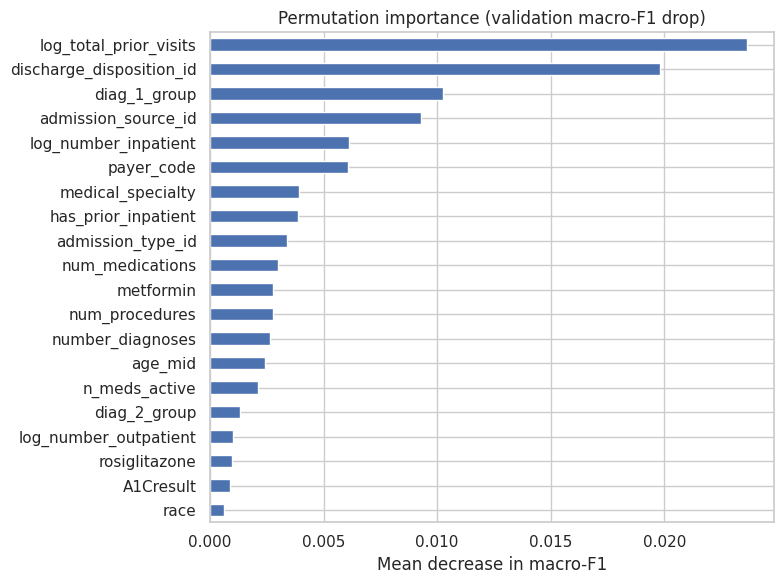

,importance
log_total_prior_visits,0.0236
discharge_disposition_id,0.0198
diag_1_group,0.0102
admission_source_id,0.0093
log_number_inpatient,0.0061
payer_code,0.0061
medical_specialty,0.0039
has_prior_inpatient,0.0039
admission_type_id,0.0034
num_medications,0.0030


ML-11 | HistGradientBoosting top-20 features   | val macro-F1 0.4412 | val acc 0.4992 | val AUC 0.6639 | train-val F1 gap +0.023 | 16s


In [ ]:
from sklearn.inspection import permutation_importance

hgb_id = max((r for r in EXPERIMENT_LOG if r["name"] == "HistGradientBoosting tuned"), key=lambda r: r["val_f1_macro"])["exp_id"]
hgb_best = FITTED[hgb_id]

perm = permutation_importance(hgb_best, X_va_eng, y_va, scoring="f1_macro", n_repeats=3,
                              random_state=SEED, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X_va_eng.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))
imp.head(20)[::-1].plot(kind="barh", ax=ax)
ax.set(title="Permutation importance (validation macro-F1 drop)", xlabel="Mean decrease in macro-F1")
plt.tight_layout(); plt.savefig(FIG_DIR / "permutation_importance.png", dpi=200); plt.show()
display(imp.head(20).round(4).to_frame("importance"))

TOP_K = 20
top_cols = imp.head(TOP_K).index.tolist()
X_tr_sel, X_va_sel = X_tr_eng[top_cols], X_va_eng[top_cols]
tuned_clf = clone(hgb_best.named_steps["clf"])
run_experiment(f"HistGradientBoosting top-{TOP_K} features",
               make_pipeline(X_tr_sel, tuned_clf), X_tr_sel, y_tr, X_va_sel, y_va, f"engineered top-{TOP_K}",
               {"model": "HistGradientBoosting", "source": hgb_id, "selected_by": "permutation importance",
                "features": top_cols})

**Interpretation (write your own):** Which features matter most, and do they agree with the literature (prior inpatient visits, number of diagnoses, age, discharge type)? Did your engineered features rank highly? Did cutting down to 20 features hurt performance, and what does that say about redundancy in the full feature set?

### 6.5 Experiment table and best traditional model
The table below is the traditional-ML half of the experiment table required by the rubric. It is saved to Drive as `experiment_log.csv`, and the matching W&B offline runs are in the `wandb/` folder.

In [ ]:
pd.set_option("display.max_colwidth", 80, "display.width", 250)
exp_table = pd.DataFrame(EXPERIMENT_LOG)
show_cols = ["exp_id", "name", "feature_set", "train_f1_macro", "val_f1_macro", "f1_gap_train_minus_val",
             "val_accuracy", "val_roc_auc_ovr_macro", "val_recall_lt30", "val_auc_lt30", "fit_time_s"]
display(exp_table[show_cols].sort_values("val_f1_macro", ascending=False).reset_index(drop=True))

,exp_id,name,feature_set,train_f1_macro,val_f1_macro,f1_gap_train_minus_val,val_accuracy,val_roc_auc_ovr_macro,val_recall_lt30,val_auc_lt30,fit_time_s
0,ML-10,RandomForest tuned,engineered,0.7635,0.4523,0.3112,0.5523,0.6657,0.1889,0.6697,897.8
1,ML-09,HistGradientBoosting tuned,engineered,0.4785,0.4442,0.0343,0.5037,0.6655,0.4064,0.6681,441.7
2,ML-11,HistGradientBoosting top-20 features,engineered top-20,0.4643,0.4412,0.0230,0.4992,0.6639,0.4160,0.6696,16.4
3,ML-05,LogReg balanced class weights,engineered,0.4435,0.4309,0.0126,0.4961,0.6528,0.3838,0.6562,18.1
4,ML-07,HistGradientBoosting default,engineered,0.4474,0.4004,0.0470,0.5823,0.6713,0.0286,0.6684,27.2
5,ML-01,LogReg default,baseline,0.3870,0.3850,0.0020,0.5769,0.6635,0.0232,0.6645,36.7
6,ML-02,LogReg default,engineered,0.3900,0.3844,0.0056,0.5774,0.6583,0.0143,0.6578,15.8
7,ML-03,RandomForest default,baseline,1.0000,0.3811,0.6189,0.5778,0.6602,0.0048,0.6506,54.5
8,ML-06,RandomForest balanced_subsample,engineered,1.0000,0.3790,0.6210,0.5743,0.6590,0.0054,0.6585,50.0
9,ML-04,RandomForest default,engineered,1.0000,0.3778,0.6222,0.5728,0.6583,0.0030,0.6542,48.4


In [ ]:
best_row = max(EXPERIMENT_LOG, key=lambda r: r["val_f1_macro"])
best_id = best_row["exp_id"]
best_pipe = FITTED[best_id]
best_cols = list(top_cols) if "top-" in best_row["feature_set"] else list(X_tr_eng.columns)
print(f"Best traditional model on validation macro-F1: {best_id} - {best_row['name']} "
      f"(macro-F1 {best_row['val_f1_macro']}, accuracy {best_row['val_accuracy']}, AUC {best_row['val_roc_auc_ovr_macro']})")

joblib.dump({"experiment_id": best_id, "name": best_row["name"], "pipeline": best_pipe,
             "feature_columns": best_cols, "label_map": LABEL_MAP},
            MODEL_DIR / "best_traditional_ml.joblib")
print("Saved:", MODEL_DIR / "best_traditional_ml.joblib")
print("Experiment table saved:", EXP_CSV)

Best traditional model on validation macro-F1: ML-10 - RandomForest tuned (macro-F1 0.4523, accuracy 0.5523, AUC 0.6657)
Saved: /content/drive/MyDrive/diabetes_project/saved_models/best_traditional_ml.joblib
Experiment table saved: /content/drive/MyDrive/diabetes_project/experiment_log.csv


In [ ]:
from sklearn.dummy import DummyClassifier

run_experiment("Majority-class baseline (Dummy)",
               make_pipeline(X_tr_eng, DummyClassifier(strategy="prior")),
               X_tr_eng, y_tr, X_va_eng, y_va, "engineered",
               {"model": "DummyClassifier", "strategy": "prior"})

for r in EXPERIMENT_LOG:
    if "tuned" in r["name"]:
        print(r["exp_id"], r["name"], json.loads(r["params"])["best_params"])

print("Best model file size (MB):", round((MODEL_DIR / "best_traditional_ml.joblib").stat().st_size / 1e6, 1))

ML-12 | Majority-class baseline (Dummy)        | val macro-F1 0.2319 | val acc 0.5335 | val AUC 0.5000 | train-val F1 gap -0.002 | 4s
ML-09 HistGradientBoosting tuned {'clf__min_samples_leaf': 20, 'clf__max_leaf_nodes': 15, 'clf__max_iter': 200, 'clf__max_depth': 6, 'clf__learning_rate': 0.05, 'clf__l2_regularization': 1.0, 'clf__class_weight': 'balanced'}
ML-10 RandomForest tuned {'clf__n_estimators': 200, 'clf__min_samples_leaf': 5, 'clf__max_features': 'sqrt', 'clf__max_depth': 20, 'clf__class_weight': 'balanced_subsample'}
Best model file size (MB): 129.4


In [ ]:
joblib.dump(FITTED["ML-10"], MODEL_DIR / "rf_tuned_extra.joblib")   # optional: keep the forest too

chosen_id = "ML-09"
chosen_row = next(r for r in EXPERIMENT_LOG if r["exp_id"] == chosen_id)
joblib.dump({"experiment_id": chosen_id, "name": chosen_row["name"], "pipeline": FITTED[chosen_id],
             "feature_columns": list(X_tr_eng.columns), "label_map": LABEL_MAP},
            MODEL_DIR / "best_traditional_ml.joblib")
print("Saved", chosen_id, "-", round((MODEL_DIR / "best_traditional_ml.joblib").stat().st_size / 1e6, 2), "MB")

Saved ML-09 - 0.82 MB


**Interpretation (write your own):** Summarise Section 6 in a paragraph: which approach won, by how much, and was the gain from features, class weighting, the algorithm or tuning? Be honest about how modest the absolute scores are; readmission is hard to predict from administrative data, and explaining *why* (information missing from the data, noisy labels, class overlap) is part of the error analysis in Section 8.

## 7. Deep learning with `tf.data` *(Day 3)*

## 8. Evaluation and error analysis *(Day 4)*

## 9. Experiment table and conclusions *(Day 4)*